Research question: may people live in the Mars?

In [91]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

In [92]:
data = pd.read_excel("mars_weather_cleaned.xlsx")

data

,DAY,TIME HHMM,DEW PT C,TEMP C,PRESSURE mb,H20 PARTIAL PRES mb,RELATIVE HUM (%)
0,2024-01-01,00:30:00,2.7,8.8,905.3,7.5,63
1,2024-01-01,01:00:00,3.1,8.2,905.4,7.7,66
2,2024-01-01,01:30:00,2.8,7.5,905.4,7.5,70
3,2024-01-01,02:00:00,2.6,7.1,905.6,7.4,72
4,2024-01-01,02:30:00,2.3,6.6,905.6,7.3,73
...,...,...,...,...,...,...,...
17400,2024-12-29,21:59:00,-6.4,13.5,906.2,3.9,20
17401,2024-12-29,22:29:00,-6.6,13.5,906.2,3.9,17
17402,2024-12-29,22:59:00,-6.9,13.5,906.3,3.8,17
17403,2024-12-29,23:29:00,-7.6,13.4,906.3,3.6,18


In [93]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17405 entries, 0 to 17404
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   DAY                  17405 non-null  datetime64[ns]
 1   TIME HHMM            17405 non-null  object        
 2   DEW PT C             17405 non-null  float64       
 3   TEMP C               17403 non-null  float64       
 4   PRESSURE mb          17405 non-null  float64       
 5   H20 PARTIAL PRES mb  17403 non-null  float64       
 6   RELATIVE HUM (%)     17405 non-null  int64         
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 952.0+ KB


In [5]:
data.describe()

,DAY,DEW PT C,TEMP C,PRESSURE mb,H20 PARTIAL PRES mb,RELATIVE HUM (%)
count,17405,17405.000000,17403.000000,17405.000000,17403.000000,17405.000000
mean,2024-06-30 07:55:58.414248960,-1.031393,18.752870,902.422649,6.294610,32.376444
min,2024-01-01 00:00:00,-20.900000,-4.800000,889.500000,1.200000,2.000000
25%,2024-03-31 00:00:00,-4.400000,10.000000,899.700000,4.600000,16.000000
50%,2024-07-01 00:00:00,-0.400000,17.400000,902.300000,6.100000,26.000000
75%,2024-09-29 00:00:00,3.300000,27.100000,905.200000,7.900000,44.000000
max,2024-12-29 00:00:00,18.000000,44.200000,918.300000,20.700000,100.000000
std,NaN,6.345165,10.496572,4.086641,2.658161,21.566586


In [6]:
data["DAY"] = pd.to_datetime(data["DAY"])

data["DATE"] = data["DAY"].dt.date

In [7]:
data = data.drop(columns=["TIME HHMM"])

In [8]:
data

,DAY,DEW PT C,TEMP C,PRESSURE mb,H20 PARTIAL PRES mb,RELATIVE HUM (%),DATE
0,2024-01-01,2.7,8.8,905.3,7.5,63,2024-01-01
1,2024-01-01,3.1,8.2,905.4,7.7,66,2024-01-01
2,2024-01-01,2.8,7.5,905.4,7.5,70,2024-01-01
3,2024-01-01,2.6,7.1,905.6,7.4,72,2024-01-01
4,2024-01-01,2.3,6.6,905.6,7.3,73,2024-01-01
...,...,...,...,...,...,...,...
17400,2024-12-29,-6.4,13.5,906.2,3.9,20,2024-12-29
17401,2024-12-29,-6.6,13.5,906.2,3.9,17,2024-12-29
17402,2024-12-29,-6.9,13.5,906.3,3.8,17,2024-12-29
17403,2024-12-29,-7.6,13.4,906.3,3.6,18,2024-12-29


In [9]:
data = data.drop(columns=["DAY"])

In [10]:
import pandas as pd
data["DATE"] = pd.to_datetime(data["DATE"])

# группируем по дате и считаем среднее
data = data.groupby("DATE").mean(numeric_only=True)

In [11]:
data

,DEW PT C,TEMP C,PRESSURE mb,H20 PARTIAL PRES mb,RELATIVE HUM (%)
DATE,,,,,
2024-01-01,0.600000,6.085106,907.226596,6.477660,71.468085
2024-01-02,-0.410638,7.489362,903.512766,6.089362,60.319149
2024-01-03,-5.278723,5.244681,903.782979,4.231915,50.297872
2024-01-04,-5.527660,5.300000,907.346809,4.178723,50.617021
2024-01-05,-10.795745,6.336170,906.825532,2.797872,29.510638
...,...,...,...,...,...
2024-12-25,0.768750,13.025000,900.650000,6.762500,27.479167
2024-12-26,0.602083,11.179167,904.956250,6.497917,27.458333
2024-12-27,-1.166667,11.252083,905.652083,5.818750,24.708333


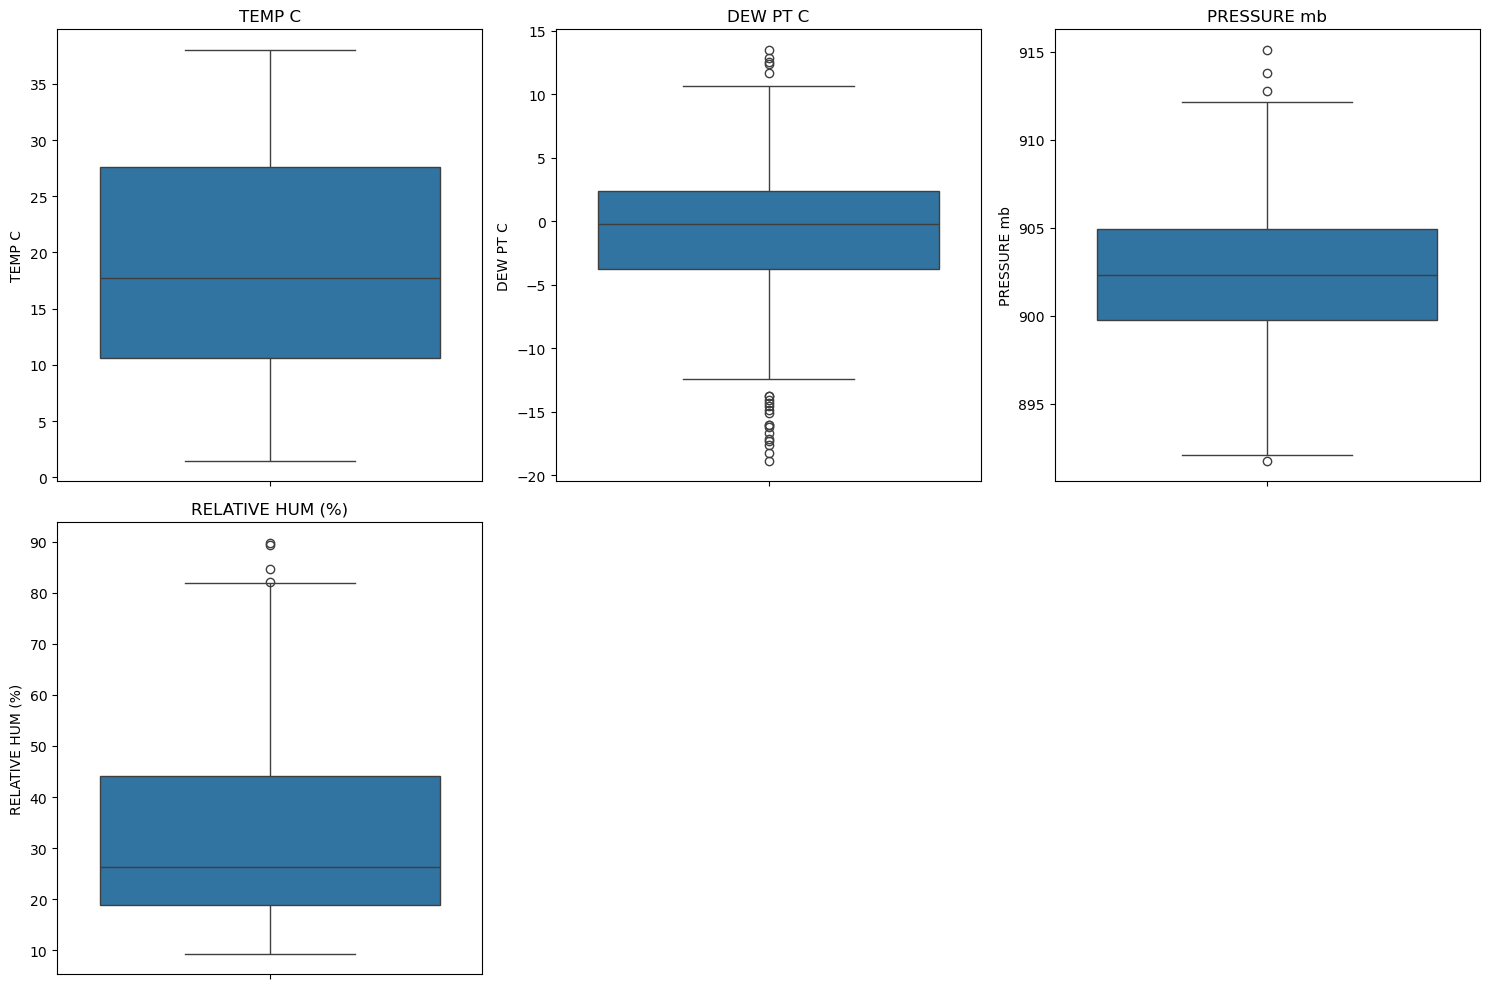

In [12]:
cols = ['TEMP C', 'DEW PT C', 'PRESSURE mb', 'RELATIVE HUM (%)']


fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes = axes.flatten()


for i, col in enumerate(cols):
    sns.boxplot(y=col, data=data, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_ylabel(col)

for j in range(len(cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

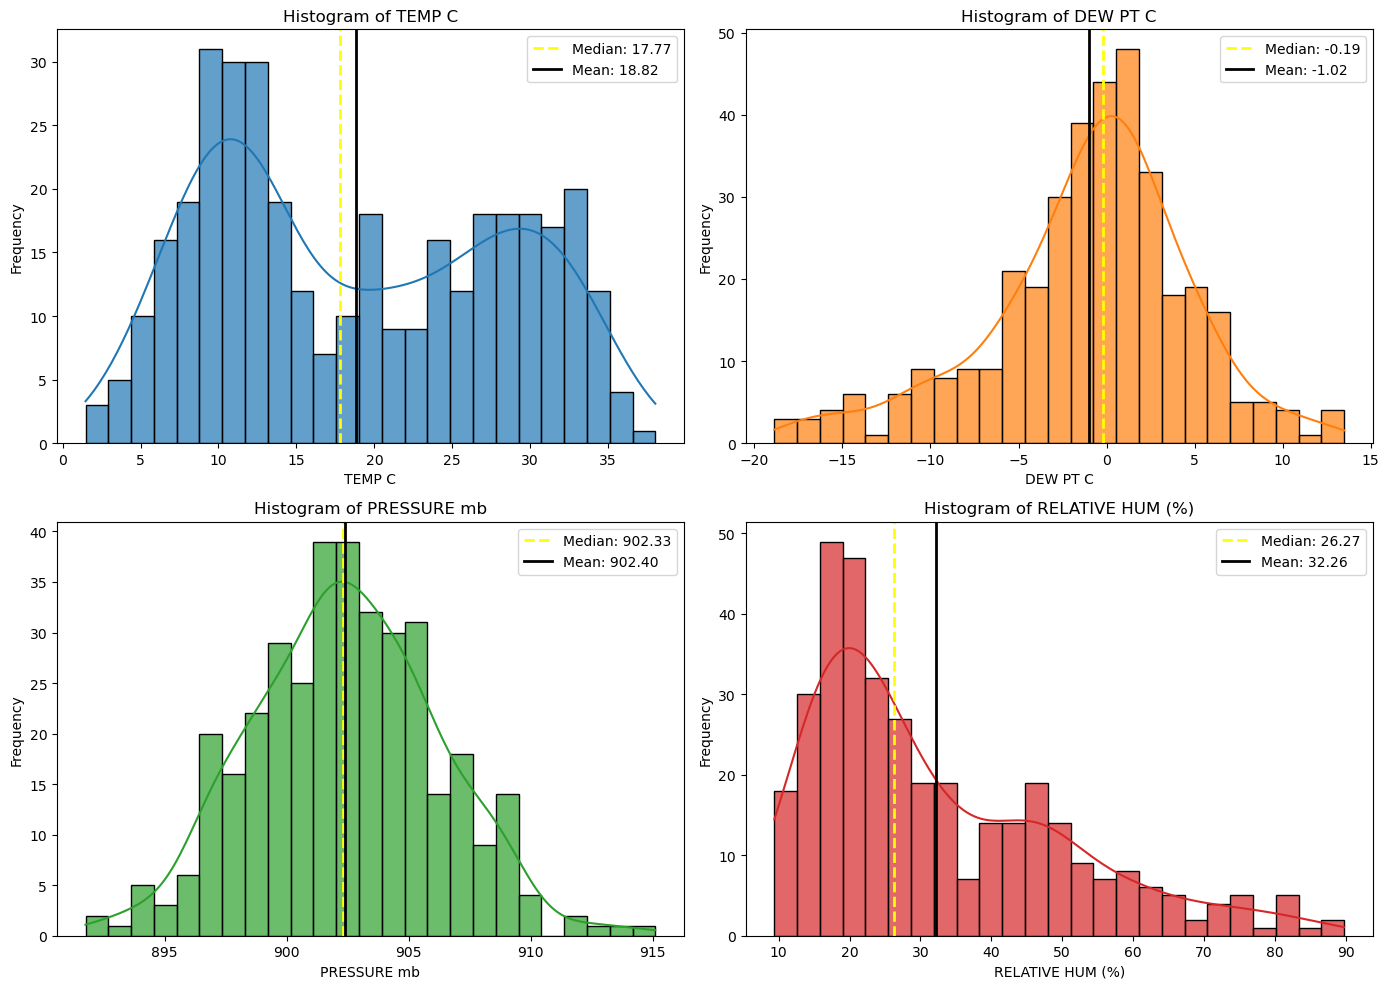

In [13]:
cols = ['TEMP C', 'DEW PT C', 'PRESSURE mb', 'RELATIVE HUM (%)']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for i, col in enumerate(cols):
    sns.histplot(data=data, x=col, bins=25, kde=True,
                 color=colors[i], ax=axes[i], alpha=0.7)
    median_val = data[col].median()
    mean_val = data[col].mean()
    axes[i].axvline(median_val, color='yellow', linestyle='--', linewidth=2,
                    label=f'Median: {median_val:.2f}')
    axes[i].axvline(mean_val, color='black', linestyle='-', linewidth=2,
                    label=f'Mean: {mean_val:.2f}')
    axes[i].set_title(f"Histogram of {col}", fontsize=12)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")
    axes[i].legend()

plt.tight_layout()
plt.show()


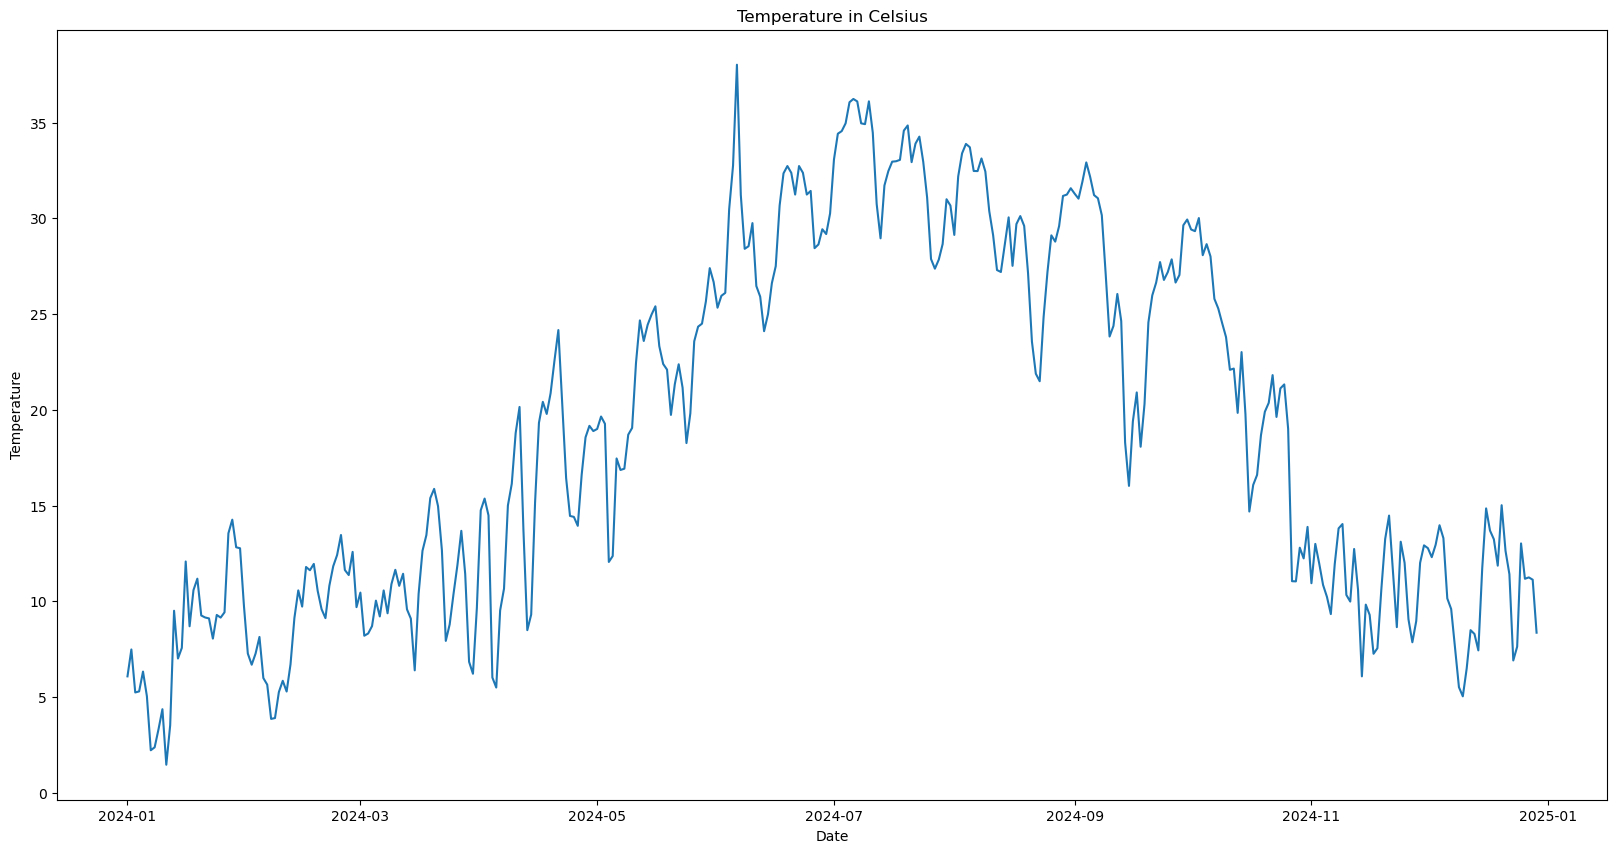

In [14]:
# Plot time series
plt.figure(figsize=(20,10))
plt.plot(data['TEMP C'], label="")
plt.title("Temperature in Celsius")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.show()

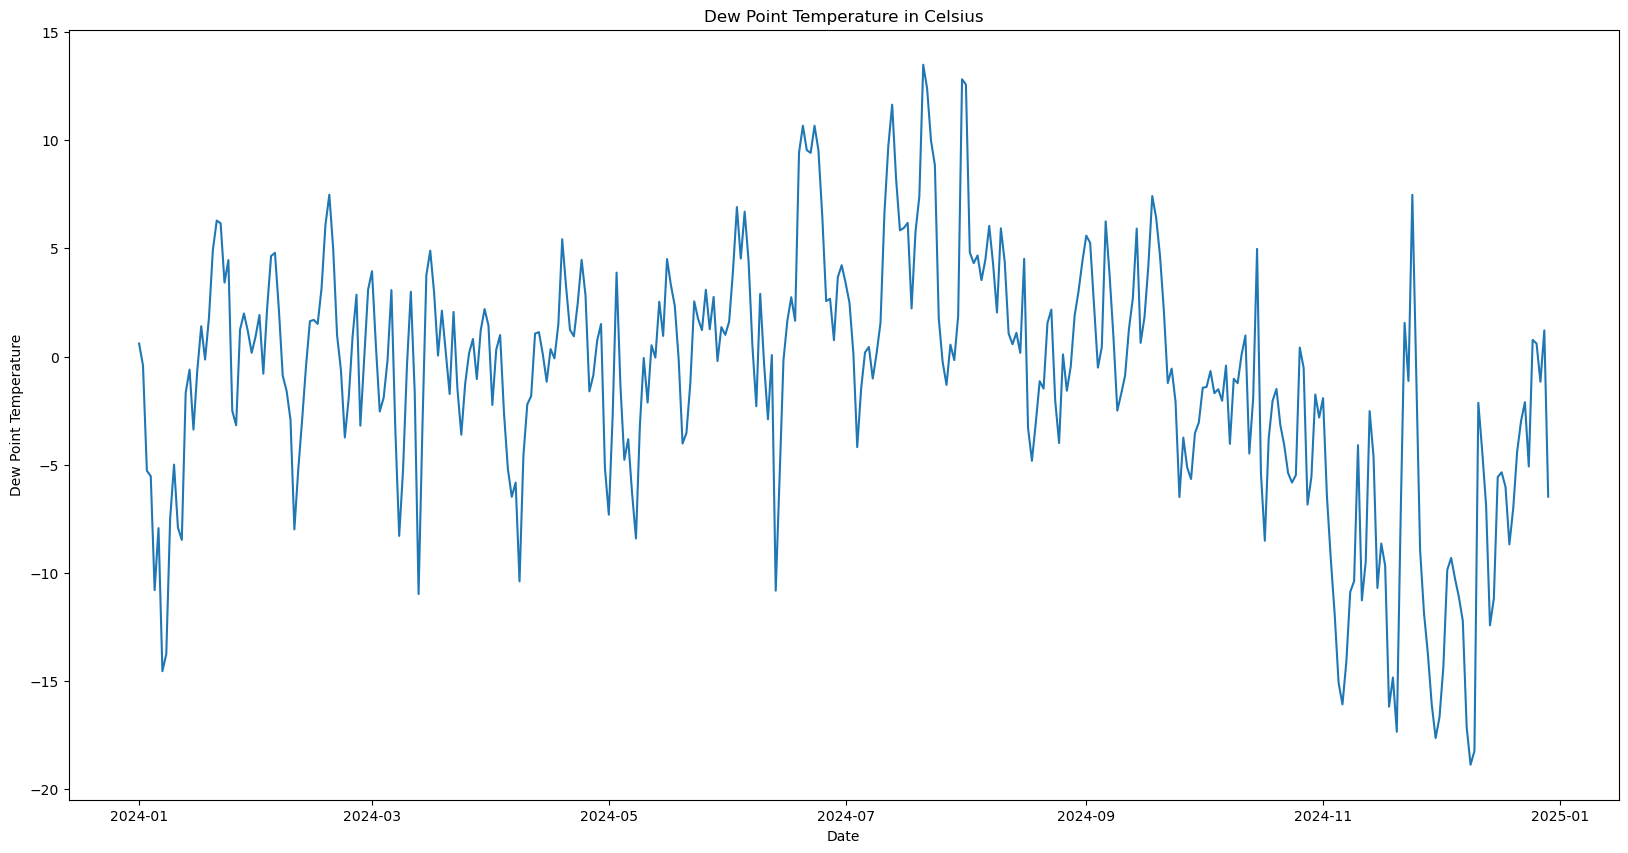

In [15]:
# Plot time series
plt.figure(figsize=(20,10))
plt.plot(data['DEW PT C'], label="")
plt.title("Dew Point Temperature in Celsius")
plt.xlabel("Date")
plt.ylabel("Dew Point Temperature")
plt.show()

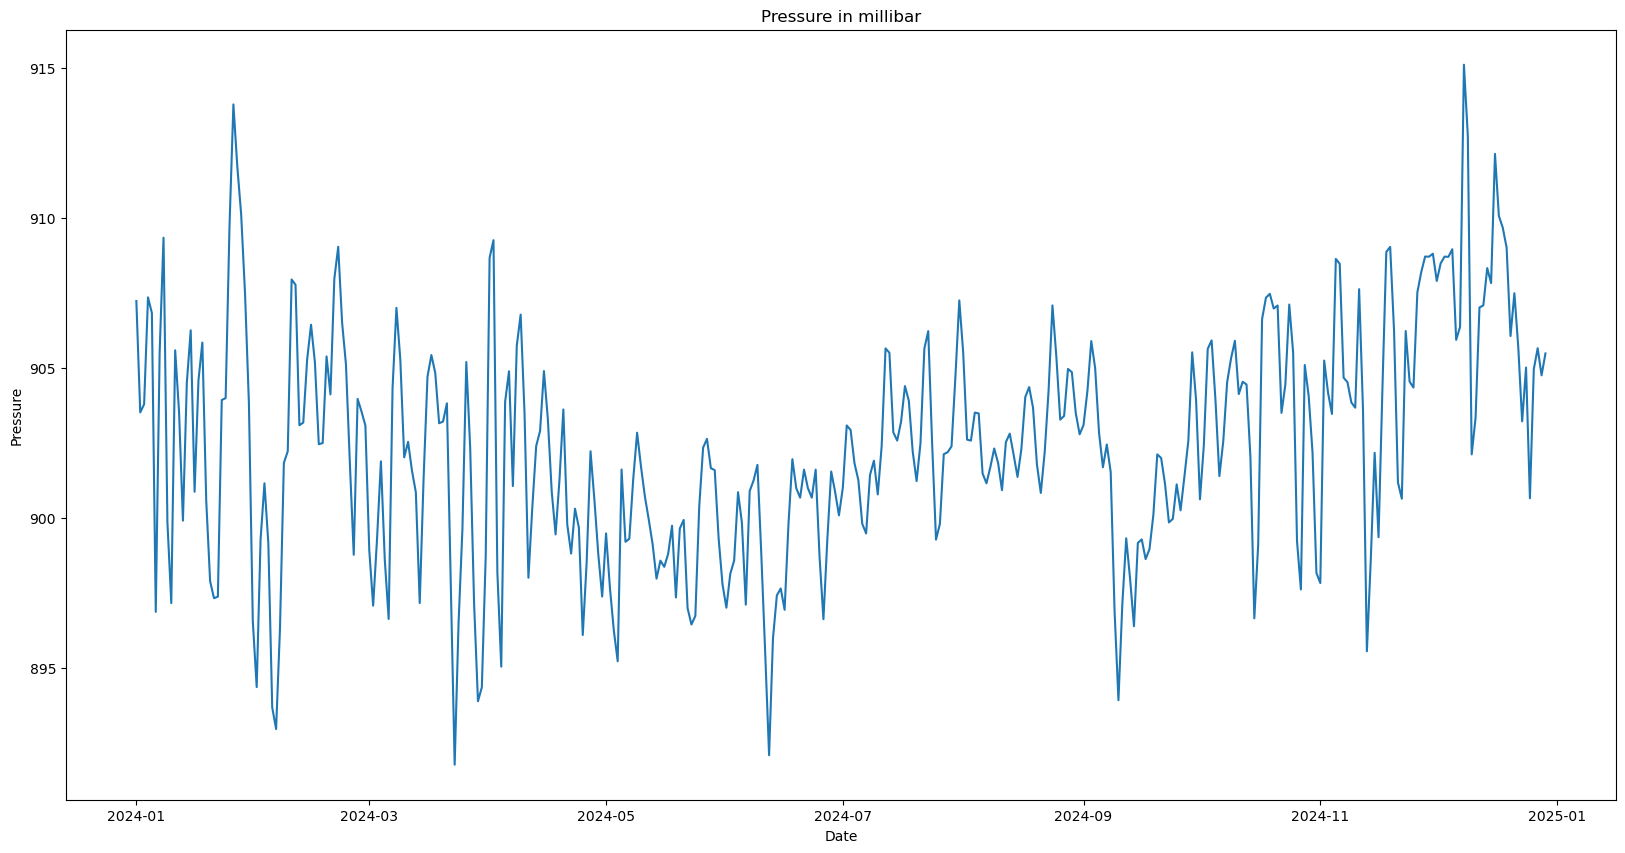

In [16]:
plt.figure(figsize=(20,10))
plt.plot(data['PRESSURE mb'], label="")
plt.title("Pressure in millibar")
plt.xlabel("Date")
plt.ylabel("Pressure")
plt.show()

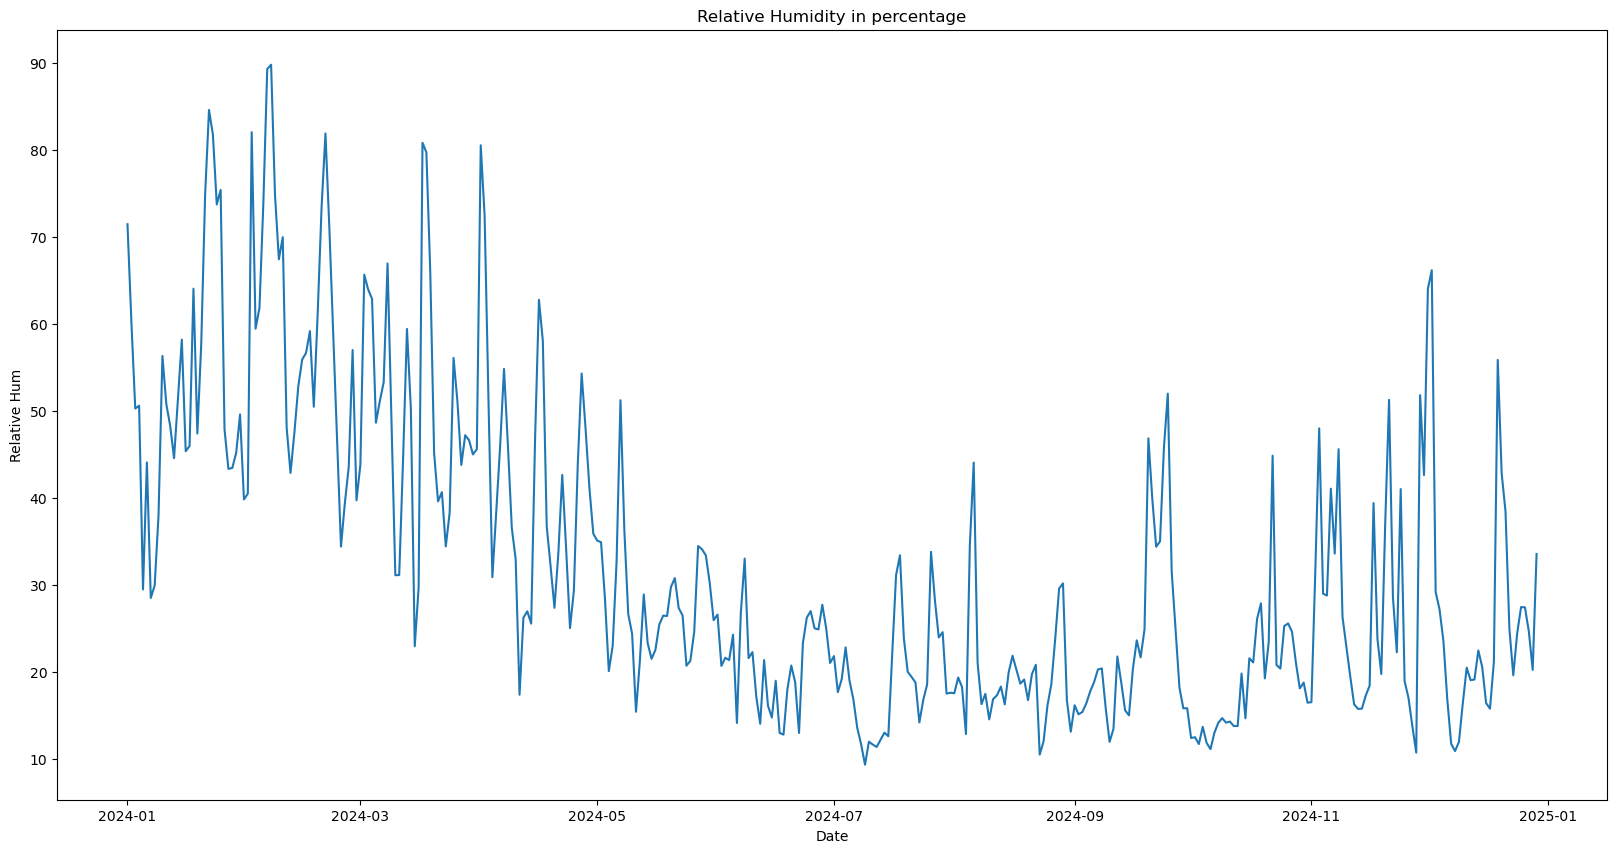

In [17]:
plt.figure(figsize=(20,10))
plt.plot(data['RELATIVE HUM (%)'], label="")
plt.title("Relative Humidity in percentage")
plt.xlabel("Date")
plt.ylabel("Relative Hum")
plt.show()

In [18]:
data = data.copy()

data['SMA_10'] = data['TEMP C'].rolling(window=10, min_periods=1).mean()
data['CMA'] = data['TEMP C'].expanding().mean()
data['EMA_0.3'] = data['TEMP C'].ewm(alpha=0.3, adjust=False).mean()

Text(0, 0.5, 'Temperature')

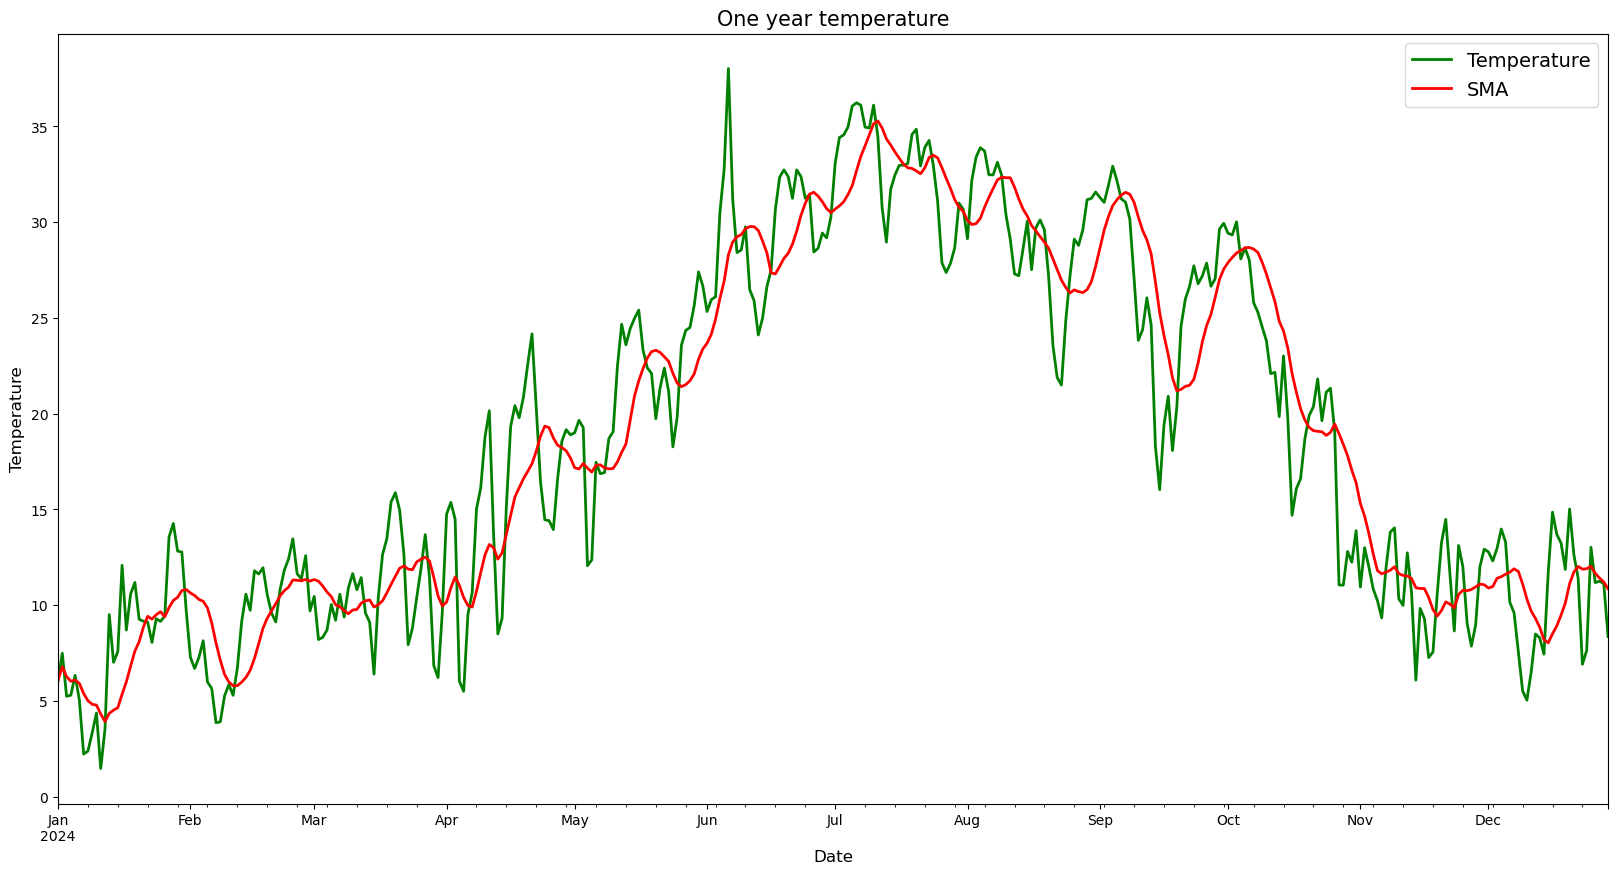

In [19]:
colors = ['green', 'red']

data[['TEMP C', 'SMA_10']].plot(color=colors, linewidth=2, figsize=(20,10))
plt.legend(labels =['Temperature', 'SMA'], fontsize=14)
plt.title('One year temperature', fontsize=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Temperature', fontsize=12)

Text(0, 0.5, 'Temperature')

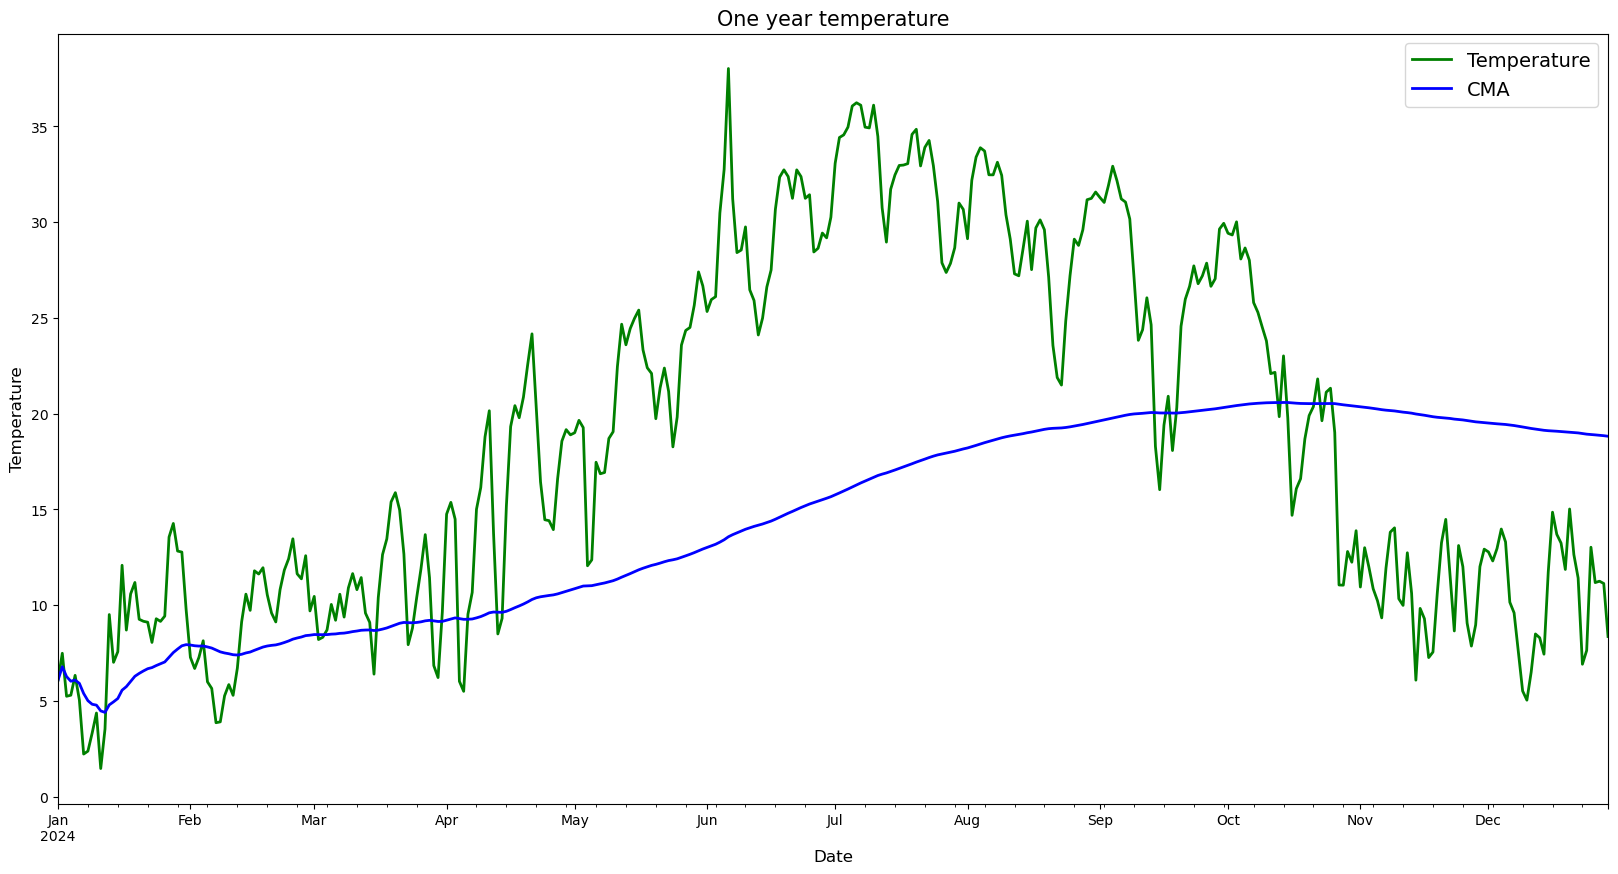

In [20]:
colors = ['green', 'blue']

data[['TEMP C', 'CMA']].plot(color=colors, linewidth=2, figsize=(20,10))
plt.legend(labels =['Temperature', 'CMA'], fontsize=14)
plt.title('One year temperature', fontsize=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Temperature', fontsize=12)

Text(0, 0.5, 'Temperature')

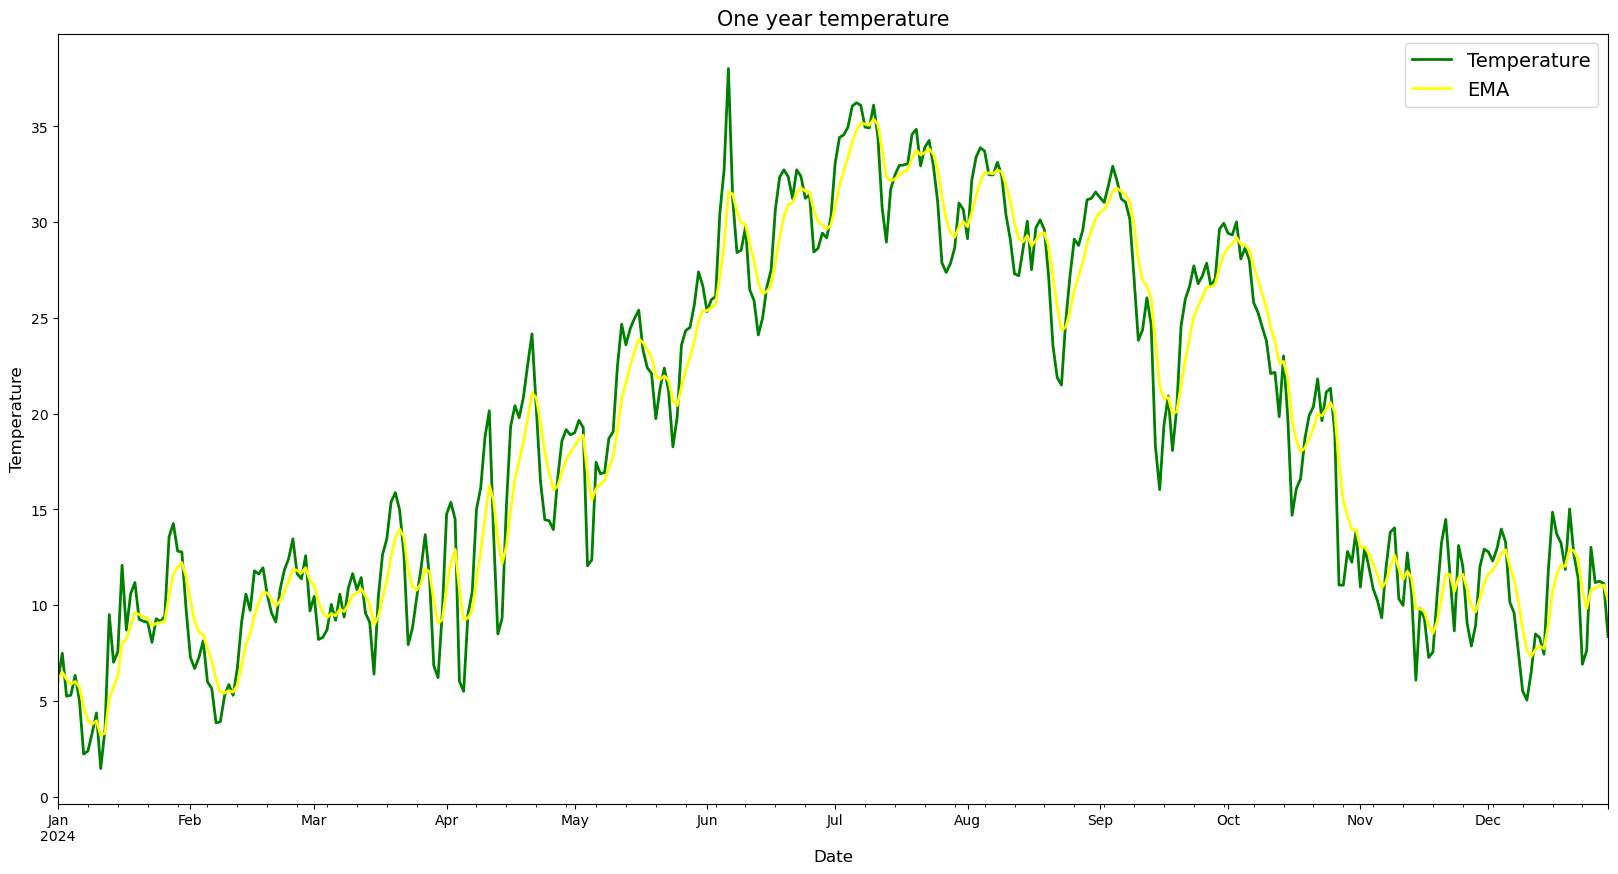

In [21]:
colors = ['green', 'yellow']

data[['TEMP C', 'EMA_0.3']].plot(color=colors, linewidth=2, figsize=(20,10))
plt.legend(labels =['Temperature', 'EMA'], fontsize=14)
plt.title('One year temperature', fontsize=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Temperature', fontsize=12)

In [22]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(data['TEMP C'])
print("ADF Statistic:", result[0])
print("p-value:", result[1])
# if p-value > 0.05, the series is not stationary.

ADF Statistic: -1.6751223020579513
p-value: 0.44397363415833596


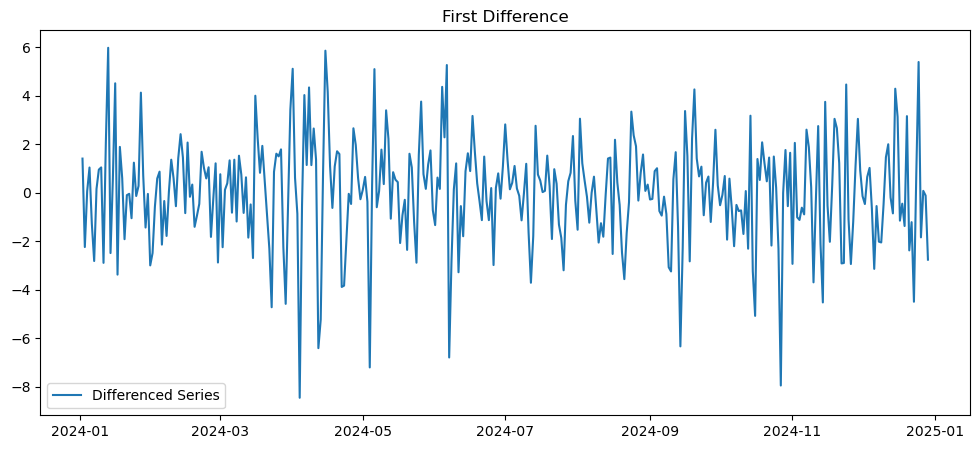

ADF Statistic after differencing: -9.84728894707027
p-value after differencing: 4.5836556908128405e-17


In [23]:
data_diff = data['TEMP C'].diff().dropna()
plt.figure(figsize=(12,5))
plt.plot(data_diff, label="Differenced Series")
plt.title("First Difference")
plt.legend()
plt.show()
result_diff = adfuller(data_diff)
print("ADF Statistic after differencing:", result_diff[0])
print("p-value after differencing:", result_diff[1])

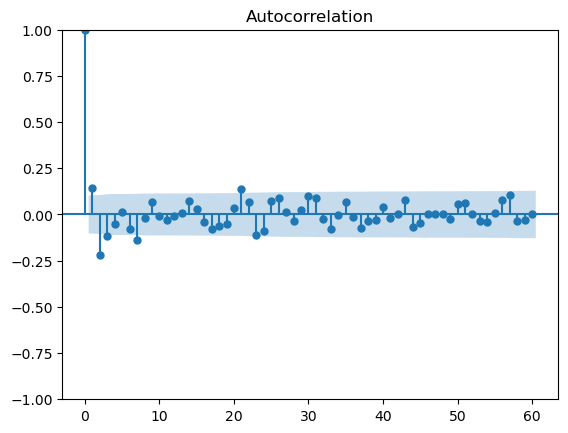

In [24]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
    
plot_acf(data_diff, lags=60)
plt.show()

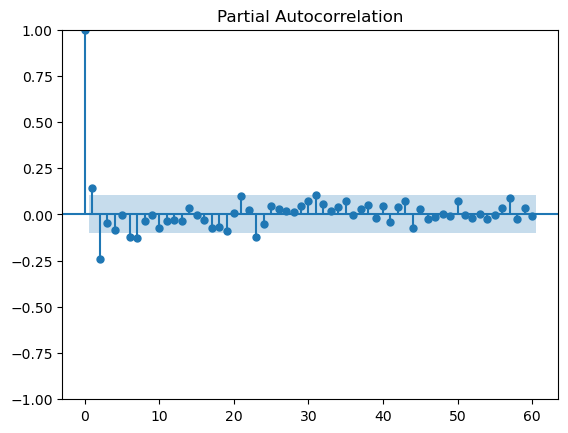

In [25]:
plot_pacf(data_diff, lags=60)
plt.show()

In [26]:
from statsmodels.tsa.arima.model import ARIMA
model = ARIMA(data['TEMP C'], order=(3,1,3))
model_fit = model.fit()
print(model_fit.summary())

C:\Users\tanir_v5tvqiw\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\tanir_v5tvqiw\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\tanir_v5tvqiw\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                 TEMP C   No. Observations:                  364
Model:                 ARIMA(3, 1, 3)   Log Likelihood                -772.272
Date:                Thu, 12 Nov 2026   AIC                           1558.544
Time:                        10:35:09   BIC                           1585.805
Sample:                    01-01-2024   HQIC                          1569.380
                         - 12-29-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.5344      0.155      9.897      0.000       1.231       1.838
ar.L2         -0.3944      0.288     -1.369      0.171      -0.959       0.170
ar.L3         -0.1620      0.144     -1.125      0.2

In [27]:
from sklearn.metrics import r2_score
y_true = data['TEMP C']
y_pred = model_fit.fittedvalues
r2 = r2_score(y_true[1:], y_pred[1:])
print("R²:", r2)

R²: 0.9533880562331672


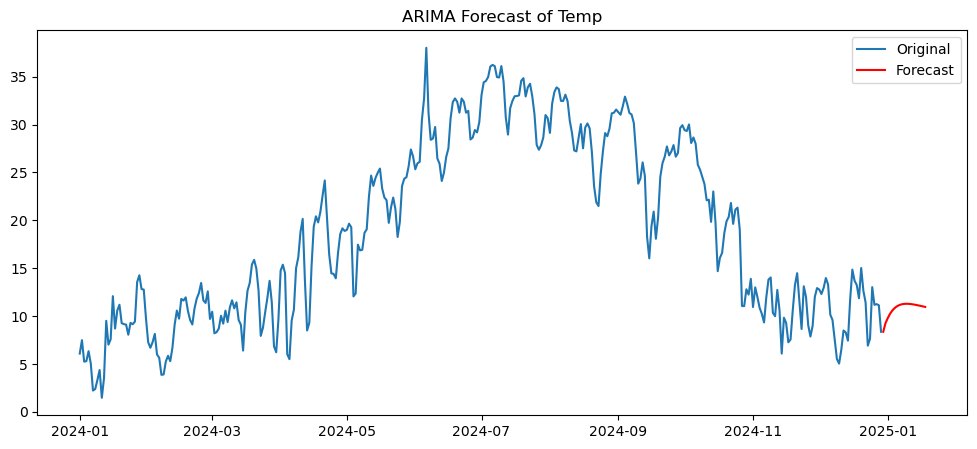

In [28]:
forecast = model_fit.forecast(steps = 20)

plt.figure(figsize=(12,5))
plt.plot(data['TEMP C'], label="Original")
plt.plot(forecast.index, forecast, label="Forecast", color="red")
plt.legend()
plt.title("ARIMA Forecast of Temp")
plt.show()


In [96]:
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

In [97]:
data1 = pd.read_excel("mars_weather_cleaned_2.xlsx")

data1

,Date,Pres,T,T_err,Dust,Dust_err,H2Ovap,H2Ovap_err,H2Oice,H2Oice_err,CO2ice,CO2ice_err,Alt,Lat,Lon
0,2006-09-24,1878.900000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
1,2006-09-24,1658.200000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
2,2006-09-24,1463.300000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
3,2006-09-24,1291.400000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
4,2006-09-24,1139.600000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51445,2006-09-25,0.007002,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,86.413,-40.230,-138.505
51446,2006-09-25,0.006179,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,87.218,-40.189,-138.497
51447,2006-09-25,0.005453,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,88.024,-40.147,-138.489
51448,2006-09-25,0.004812,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,88.830,-40.105,-138.481


In [31]:
data1.columns

Index(['Date', '         Pres', '       T', '   T_err', '       Dust',
       '   Dust_err', '     H2Ovap', ' H2Ovap_err', '     H2Oice',
       ' H2Oice_err', '     CO2ice', ' CO2ice_err', '     Alt', '       Lat',
       '       Lon'],
      dtype='object')

In [32]:
data1.columns = data1.columns.str.strip()

print(data1.columns)

Index(['Date', 'Pres', 'T', 'T_err', 'Dust', 'Dust_err', 'H2Ovap',
       'H2Ovap_err', 'H2Oice', 'H2Oice_err', 'CO2ice', 'CO2ice_err', 'Alt',
       'Lat', 'Lon'],
      dtype='object')


In [33]:
data1 = data1.replace(-9999, np.nan)
data1 = data1.replace(-9999.0, np.nan)

In [34]:
data1.head(20)

,Date,Pres,T,T_err,Dust,Dust_err,H2Ovap,H2Ovap_err,H2Oice,H2Oice_err,CO2ice,CO2ice_err,Alt,Lat,Lon
0,2006-09-24,1878.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2006-09-24,1658.20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2006-09-24,1463.30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2006-09-24,1291.40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2006-09-24,1139.60,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2006-09-24,1005.70,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2006-09-24,887.54,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2006-09-24,783.26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2006-09-24,691.22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2006-09-24,610.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
data1 = data1.loc[:, ~data1.columns.str.contains('_err')]
data1 = data1.drop(columns=['H2Ovap'], errors='ignore')

print(data1.columns)


Index(['Date', 'Pres', 'T', 'Dust', 'H2Oice', 'CO2ice', 'Alt', 'Lat', 'Lon'], dtype='object')


In [36]:
data1

,Date,Pres,T,Dust,H2Oice,CO2ice,Alt,Lat,Lon
0,2006-09-24,1878.900000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2006-09-24,1658.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2006-09-24,1463.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2006-09-24,1291.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2006-09-24,1139.600000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
51445,2006-09-25,0.007002,NaN,NaN,NaN,NaN,86.413,-40.230,-138.505
51446,2006-09-25,0.006179,NaN,NaN,NaN,NaN,87.218,-40.189,-138.497
51447,2006-09-25,0.005453,NaN,NaN,NaN,NaN,88.024,-40.147,-138.489
51448,2006-09-25,0.004812,NaN,NaN,NaN,NaN,88.830,-40.105,-138.481


In [37]:
data1['Temp']=data1['T']-273.15

In [38]:
data1

,Date,Pres,T,Dust,H2Oice,CO2ice,Alt,Lat,Lon,Temp
0,2006-09-24,1878.900000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2006-09-24,1658.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2006-09-24,1463.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2006-09-24,1291.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2006-09-24,1139.600000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
51445,2006-09-25,0.007002,NaN,NaN,NaN,NaN,86.413,-40.230,-138.505,NaN
51446,2006-09-25,0.006179,NaN,NaN,NaN,NaN,87.218,-40.189,-138.497,NaN
51447,2006-09-25,0.005453,NaN,NaN,NaN,NaN,88.024,-40.147,-138.489,NaN
51448,2006-09-25,0.004812,NaN,NaN,NaN,NaN,88.830,-40.105,-138.481,NaN


In [39]:
data1=data1.drop(columns=['T'])

In [40]:
data1=data1.drop(columns=['Dust','H2Oice', 'CO2ice'])

In [41]:
data1 = data1.dropna(subset=["Temp"])
data1 = data1.dropna(subset=["Pres"])

In [42]:
data1

,Date,Pres,Alt,Lat,Lon,Temp
11,2006-09-24,475.070000,0.232,-23.663,27.622,-75.735
12,2006-09-24,419.250000,1.502,-23.610,27.630,-76.160
13,2006-09-24,369.980000,2.767,-23.557,27.638,-77.060
14,2006-09-24,326.510000,4.027,-23.505,27.646,-78.378
15,2006-09-24,288.140000,5.279,-23.452,27.654,-80.035
...,...,...,...,...,...,...
51429,2006-09-25,0.051739,73.540,-40.883,-138.635,-152.715
51430,2006-09-25,0.045660,74.346,-40.842,-138.627,-152.883
51431,2006-09-25,0.040294,75.151,-40.802,-138.619,-153.018
51432,2006-09-25,0.035560,75.956,-40.762,-138.611,-153.130


In [43]:
T0 = -80
P0 = 0.2
data1["Pres_kPa"] = data1["Pres"]

data1["T_score"] = np.clip((data1["Temp"] - T0) / 40, 0, 1)      
data1["P_score"] = np.clip((data1["Pres_kPa"] - P0) / 10, 0, 1) 

data1["Suitability"] = data1["T_score"] * data1["P_score"]


In [44]:
data1=data1[data1['Alt']<2]

In [45]:
data1

,Date,Pres,Alt,Lat,Lon,Temp,Pres_kPa,T_score,P_score,Suitability
11,2006-09-24,475.07,0.232,-23.663,27.622,-75.735,475.07,0.106625,1.0,0.106625
12,2006-09-24,419.25,1.502,-23.610,27.630,-76.160,419.25,0.096000,1.0,0.096000
115,2006-09-24,538.32,0.251,-25.568,27.350,-67.011,538.32,0.324725,1.0,0.324725
116,2006-09-24,475.07,1.572,-25.513,27.358,-68.120,475.07,0.297000,1.0,0.297000
221,2006-09-24,475.07,0.425,-27.339,27.094,-74.075,475.07,0.148125,1.0,0.148125
...,...,...,...,...,...,...,...,...,...,...
51041,2006-09-25,475.07,0.614,-36.637,-138.035,-83.154,475.07,0.000000,1.0,0.000000
51042,2006-09-25,419.25,1.833,-36.586,-138.026,-83.587,419.25,0.000000,1.0,0.000000
51147,2006-09-25,419.25,1.039,-38.470,-138.335,-82.998,419.25,0.000000,1.0,0.000000
51252,2006-09-25,419.25,0.369,-40.325,-138.649,-86.496,419.25,0.000000,1.0,0.000000


In [46]:
from scipy.stats import shapiro

stat, p = shapiro(data1["Suitability"].sample(300, random_state=1))
print("Shapiro p-value:", p)

Shapiro p-value: 2.578051500472559e-16


In [47]:
from scipy.stats import wilcoxon
import numpy as np

S = data1["Suitability"].dropna().to_numpy()
S0 = 0.2

diff = S - S0
diff = diff[diff != 0]

stat, p = wilcoxon(diff, alternative="greater")
print("p-value:", p)
print("mean suitability:", np.mean(S))

p-value: 2.6320435321786388e-15
mean suitability: 0.3750971343873521


In [48]:
data1 = pd.read_excel("final_mars1.xlsx")

data1

,Date,Pres,T,T_err,Dust,Dust_err,H2Ovap,H2Ovap_err,H2Oice,H2Oice_err,CO2ice,CO2ice_err,Alt,Lat,Lon
0,2006-09-24,1878.900000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
1,2006-09-24,1658.200000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
2,2006-09-24,1463.300000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
3,2006-09-24,1291.400000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
4,2006-09-24,1139.600000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51445,2006-09-25,0.007002,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,86.413,-40.230,-138.505
51446,2006-09-25,0.006179,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,87.218,-40.189,-138.497
51447,2006-09-25,0.005453,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,88.024,-40.147,-138.489
51448,2006-09-25,0.004812,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,88.830,-40.105,-138.481


In [49]:
data1.columns = data1.columns.str.strip()

print(data1.columns)

Index(['Date', 'Pres', 'T', 'T_err', 'Dust', 'Dust_err', 'H2Ovap',
       'H2Ovap_err', 'H2Oice', 'H2Oice_err', 'CO2ice', 'CO2ice_err', 'Alt',
       'Lat', 'Lon'],
      dtype='object')


In [50]:
data1 = data1.replace(-9999, np.nan)
data1 = data1.replace(-9999.0, np.nan)

In [51]:
data1 = data1.loc[:, ~data1.columns.str.contains('_err')]
data1 = data1.drop(columns=['H2Ovap'], errors='ignore')

print(data1.columns)

Index(['Date', 'Pres', 'T', 'Dust', 'H2Oice', 'CO2ice', 'Alt', 'Lat', 'Lon'], dtype='object')


In [52]:
data1['Temp']=data1['T']-273.15

In [53]:
data1=data1.drop(columns=['T'])
data1 = data1.dropna(subset=["Temp"])
data1 = data1.dropna(subset=["Pres"])
data1=data1.drop(columns=['Dust','H2Oice', 'CO2ice'])

In [54]:
data1

,Date,Pres,Alt,Lat,Lon,Temp
11,2006-09-24,475.070000,0.232,-23.663,27.622,-75.735
12,2006-09-24,419.250000,1.502,-23.610,27.630,-76.160
13,2006-09-24,369.980000,2.767,-23.557,27.638,-77.060
14,2006-09-24,326.510000,4.027,-23.505,27.646,-78.378
15,2006-09-24,288.140000,5.279,-23.452,27.654,-80.035
...,...,...,...,...,...,...
51429,2006-09-25,0.051739,73.540,-40.883,-138.635,-152.715
51430,2006-09-25,0.045660,74.346,-40.842,-138.627,-152.883
51431,2006-09-25,0.040294,75.151,-40.802,-138.619,-153.018
51432,2006-09-25,0.035560,75.956,-40.762,-138.611,-153.130


In [55]:
def lat_zone(lat):
    if abs(lat) < 30:
        return "Equatorial"
    elif abs(lat) < 60:
        return "Mid-latitude"
    else:
        return "Polar"

data1["Lat_zone"] = data1["Lat"].apply(lat_zone)


In [56]:
data1

,Date,Pres,Alt,Lat,Lon,Temp,Lat_zone
11,2006-09-24,475.070000,0.232,-23.663,27.622,-75.735,Equatorial
12,2006-09-24,419.250000,1.502,-23.610,27.630,-76.160,Equatorial
13,2006-09-24,369.980000,2.767,-23.557,27.638,-77.060,Equatorial
14,2006-09-24,326.510000,4.027,-23.505,27.646,-78.378,Equatorial
15,2006-09-24,288.140000,5.279,-23.452,27.654,-80.035,Equatorial
...,...,...,...,...,...,...,...
51429,2006-09-25,0.051739,73.540,-40.883,-138.635,-152.715,Mid-latitude
51430,2006-09-25,0.045660,74.346,-40.842,-138.627,-152.883,Mid-latitude
51431,2006-09-25,0.040294,75.151,-40.802,-138.619,-153.018,Mid-latitude
51432,2006-09-25,0.035560,75.956,-40.762,-138.611,-153.130,Mid-latitude


In [57]:
data1[data1['Lat_zone']=='Equatorial']

,Date,Pres,Alt,Lat,Lon,Temp,Lat_zone
11,2006-09-24,475.070000,0.232,-23.663,27.622,-75.735,Equatorial
12,2006-09-24,419.250000,1.502,-23.610,27.630,-76.160,Equatorial
13,2006-09-24,369.980000,2.767,-23.557,27.638,-77.060,Equatorial
14,2006-09-24,326.510000,4.027,-23.505,27.646,-78.378,Equatorial
15,2006-09-24,288.140000,5.279,-23.452,27.654,-80.035,Equatorial
...,...,...,...,...,...,...,...
50904,2006-09-25,0.051739,75.378,-29.536,-136.874,-136.042,Equatorial
50905,2006-09-25,0.045660,76.298,-29.491,-136.867,-136.200,Equatorial
50906,2006-09-25,0.040294,77.218,-29.445,-136.859,-136.298,Equatorial
50907,2006-09-25,0.035560,78.137,-29.399,-136.852,-136.369,Equatorial


In [58]:
data1[data1['Lat_zone']=='Polar']

,Date,Pres,Alt,Lat,Lon,Temp,Lat_zone
2007,2006-09-24,419.250000,1.142,-60.919,20.477,-126.155,Polar
2008,2006-09-24,369.980000,2.082,-60.879,20.493,-126.104,Polar
2009,2006-09-24,326.510000,3.023,-60.839,20.509,-126.007,Polar
2010,2006-09-24,288.140000,3.966,-60.799,20.524,-125.848,Polar
2011,2006-09-24,254.290000,4.911,-60.759,20.540,-125.608,Polar
...,...,...,...,...,...,...,...
46923,2006-09-25,0.016797,92.043,63.197,-122.036,-129.988,Polar
46924,2006-09-25,0.014824,93.005,63.241,-122.026,-130.254,Polar
46925,2006-09-25,0.013082,93.966,63.285,-122.016,-130.410,Polar
46926,2006-09-25,0.011545,94.927,63.328,-122.006,-130.514,Polar


In [59]:
data1[data1['Lat_zone']=='Mid-latitude']

,Date,Pres,Alt,Lat,Lon,Temp,Lat_zone
439,2006-09-24,174.770000,10.965,-30.588,26.621,-91.672,Mid-latitude
440,2006-09-24,154.230000,12.134,-30.538,26.630,-93.015,Mid-latitude
441,2006-09-24,136.110000,13.298,-30.488,26.638,-93.867,Mid-latitude
442,2006-09-24,120.120000,14.457,-30.438,26.646,-94.516,Mid-latitude
443,2006-09-24,106.000000,15.613,-30.389,26.655,-95.067,Mid-latitude
...,...,...,...,...,...,...,...
51429,2006-09-25,0.051739,73.540,-40.883,-138.635,-152.715,Mid-latitude
51430,2006-09-25,0.045660,74.346,-40.842,-138.627,-152.883,Mid-latitude
51431,2006-09-25,0.040294,75.151,-40.802,-138.619,-153.018,Mid-latitude
51432,2006-09-25,0.035560,75.956,-40.762,-138.611,-153.130,Mid-latitude


In [60]:
data1=data1[data1['Alt']<3]

In [61]:
from scipy.stats import shapiro
p = shapiro(data1[data1['Lat_zone']=='Equatorial']['Temp']).pvalue
print(f"Shapiro Test: Statistic p-value ={p} ") 

if p > 0.05:
    print("✅ Data looks normal (fail to reject H₀)")
else:
    print("❌ Data not normal (reject H₀)")

Shapiro Test: Statistic p-value =0.0015719895707228039 
❌ Data not normal (reject H₀)


In [62]:
from scipy.stats import shapiro
p = shapiro(data1[data1['Lat_zone']=='Mid-latitude']['Temp']).pvalue
print(f"Shapiro Test: Statistic p-value ={p} ") 

if p > 0.05:
    print("✅ Data looks normal (fail to reject H₀)")
else:
    print("❌ Data not normal (reject H₀)")

Shapiro Test: Statistic p-value =3.858545643040437e-07 
❌ Data not normal (reject H₀)


In [63]:
from scipy.stats import shapiro
p = shapiro(data1[data1['Lat_zone']=='Polar']['Temp']).pvalue
print(f"Shapiro Test: Statistic p-value ={p} ") 

if p > 0.05:
    print("✅ Data looks normal (fail to reject H₀)")
else:
    print("❌ Data not normal (reject H₀)")

Shapiro Test: Statistic p-value =6.728213492555246e-16 
❌ Data not normal (reject H₀)


In [64]:
from scipy.stats import kruskal

eq = data1[data1["Lat_zone"]=="Equatorial"]["Temp"]
mid = data1[data1["Lat_zone"]=="Mid-latitude"]["Temp"]
pol = data1[data1["Lat_zone"]=="Polar"]["Temp"]

stat, p = kruskal(eq, mid, pol)
print("Kruskal–Wallis p-value:", p)

Kruskal–Wallis p-value: 0.004918376765383133


In [65]:
data2 = [eq, mid, pol]

In [66]:
import scikit_posthocs as sp

p_values = sp.posthoc_dunn(data1,val_col="Temp",group_col="Lat_zone",p_adjust="holm")

print(p_values)

              Equatorial  Mid-latitude     Polar
Equatorial      1.000000      0.716316  0.014526
Mid-latitude    0.716316      1.000000  0.006421
Polar           0.014526      0.006421  1.000000


In [67]:
print(p_values < 0.05)

              Equatorial  Mid-latitude  Polar
Equatorial         False         False   True
Mid-latitude       False         False   True
Polar               True          True  False


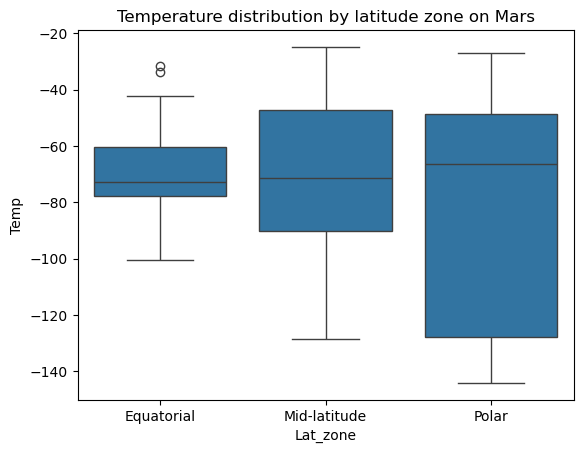

In [68]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=data1, x="Lat_zone", y="Temp")
plt.title("Temperature distribution by latitude zone on Mars")
plt.show()


In [98]:
data1 = pd.read_excel("mars_weather_cleaned_2.xlsx")

data1

,Date,Pres,T,T_err,Dust,Dust_err,H2Ovap,H2Ovap_err,H2Oice,H2Oice_err,CO2ice,CO2ice_err,Alt,Lat,Lon
0,2006-09-24,1878.900000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
1,2006-09-24,1658.200000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
2,2006-09-24,1463.300000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
3,2006-09-24,1291.400000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
4,2006-09-24,1139.600000,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,-9999.000,-9999.000,-9999.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51445,2006-09-25,0.007002,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,86.413,-40.230,-138.505
51446,2006-09-25,0.006179,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,87.218,-40.189,-138.497
51447,2006-09-25,0.005453,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,88.024,-40.147,-138.489
51448,2006-09-25,0.004812,-9999.0,-9999.0,-9999.0,-9999.0,-9999,-9999,-9999.0,-9999.0,-9999,-9999,88.830,-40.105,-138.481


In [70]:
data1.columns = data1.columns.str.strip()

print(data1.columns)

Index(['Date', 'Pres', 'T', 'T_err', 'Dust', 'Dust_err', 'H2Ovap',
       'H2Ovap_err', 'H2Oice', 'H2Oice_err', 'CO2ice', 'CO2ice_err', 'Alt',
       'Lat', 'Lon'],
      dtype='object')


In [71]:
data1 = data1.replace(-9999, np.nan)
data1 = data1.replace(-9999.0, np.nan)

In [72]:
data1 = data1.loc[:, ~data1.columns.str.contains('_err')]
data1 = data1.drop(columns=['H2Ovap'], errors='ignore')

print(data1.columns)


Index(['Date', 'Pres', 'T', 'Dust', 'H2Oice', 'CO2ice', 'Alt', 'Lat', 'Lon'], dtype='object')


In [73]:
data1['Temp']=data1['T']-273.15

In [74]:
data1

,Date,Pres,T,Dust,H2Oice,CO2ice,Alt,Lat,Lon,Temp
0,2006-09-24,1878.900000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2006-09-24,1658.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2006-09-24,1463.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2006-09-24,1291.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2006-09-24,1139.600000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
51445,2006-09-25,0.007002,NaN,NaN,NaN,NaN,86.413,-40.230,-138.505,NaN
51446,2006-09-25,0.006179,NaN,NaN,NaN,NaN,87.218,-40.189,-138.497,NaN
51447,2006-09-25,0.005453,NaN,NaN,NaN,NaN,88.024,-40.147,-138.489,NaN
51448,2006-09-25,0.004812,NaN,NaN,NaN,NaN,88.830,-40.105,-138.481,NaN


In [75]:
data1 = data1.iloc[:105]

In [76]:
data1=data1.drop(columns=['T'])
data1=data1.drop(columns=['Dust','H2Oice', 'CO2ice'])

In [77]:
data1 = data1.dropna(subset=["Temp"])
data1 = data1.dropna(subset=["Pres"])

In [78]:
def lat_zone(lat):
    if abs(lat) < 30:
        return "Equatorial"
    elif abs(lat) < 60:
        return "Mid-latitude"
    else:
        return "Polar"

data1["Lat_zone"] = data1["Lat"].apply(lat_zone)

In [79]:
data1 = data1[data1['Lat_zone']=='Equatorial']

In [80]:
data1

,Date,Pres,Alt,Lat,Lon,Temp,Lat_zone
11,2006-09-24,475.070000,0.232,-23.663,27.622,-75.735,Equatorial
12,2006-09-24,419.250000,1.502,-23.610,27.630,-76.160,Equatorial
13,2006-09-24,369.980000,2.767,-23.557,27.638,-77.060,Equatorial
14,2006-09-24,326.510000,4.027,-23.505,27.646,-78.378,Equatorial
15,2006-09-24,288.140000,5.279,-23.452,27.654,-80.035,Equatorial
...,...,...,...,...,...,...,...
89,2006-09-24,0.027694,78.282,-20.142,28.137,-165.141,Equatorial
90,2006-09-24,0.024440,79.009,-20.106,28.142,-165.414,Equatorial
91,2006-09-24,0.021568,79.734,-20.070,28.147,-165.654,Equatorial
92,2006-09-24,0.019034,80.458,-20.034,28.152,-165.863,Equatorial


In [81]:
df_alt = data1.sort_values("Alt")

In [82]:
import statsmodels.api as sm

X = sm.add_constant(df_alt["Alt"])
y = df_alt["Pres"]

model = sm.OLS(y, X).fit()

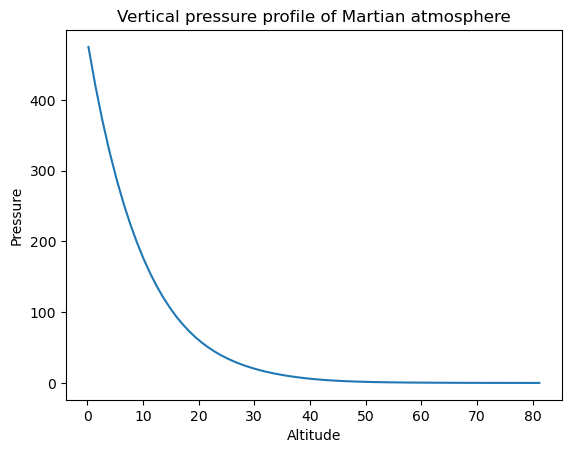

In [83]:
import matplotlib.pyplot as plt

plt.plot(df_alt["Alt"], df_alt["Pres"])
plt.xlabel("Altitude")
plt.ylabel("Pressure")
plt.title("Vertical pressure profile of Martian atmosphere")
plt.show()

In [84]:
df_alt = data1.dropna(subset=["Alt", "Pres"]).copy()
df_alt = df_alt[df_alt["Pres"] > 0] 
df_alt = df_alt.sort_values("Alt")

x = df_alt["Alt"].to_numpy()
y = df_alt["Pres"].to_numpy()

Fitted P0: 492.18536684671386 k: 0.10333714830074735


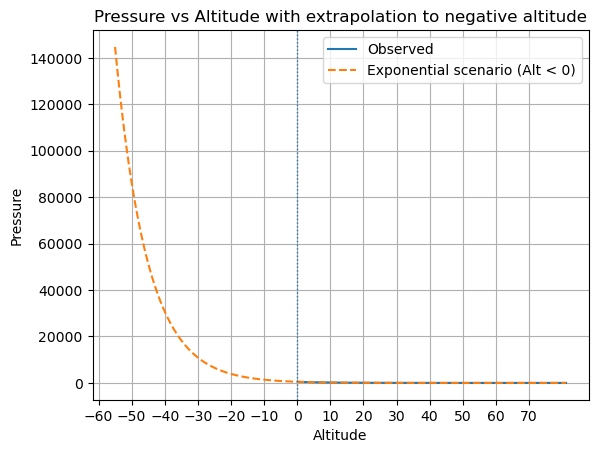

In [85]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def exp_model(alt, P0, k):
    return P0 * np.exp(-k * alt)

p0_guess = [y.max(), 0.01]
params, _ = curve_fit(exp_model, x, y, p0=p0_guess, maxfev=1000)
P0_hat, k_hat = params

print("Fitted P0:", P0_hat, "k:", k_hat)


alt_min_neg = -55
alt_max = x.max()
alt_ext = np.linspace(alt_min_neg, alt_max, 400)

pres_fit = exp_model(alt_ext, P0_hat, k_hat)


plt.figure()
plt.plot(x, y, label="Observed")
plt.plot(alt_ext, pres_fit, "--", label="Exponential scenario (Alt < 0)")
plt.axvline(0, linestyle=":", linewidth=1)
plt.xlabel("Altitude")
plt.ylabel("Pressure")
plt.title("Pressure vs Altitude with extrapolation to negative altitude")
plt.legend()
plt.xticks(range(-60, 80, 10))
plt.grid()
plt.show()

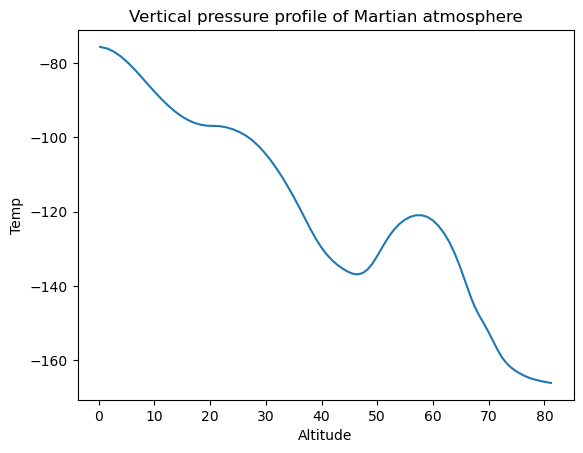

In [86]:
plt.plot(df_alt["Alt"], df_alt["Temp"])
plt.xlabel("Altitude")
plt.ylabel("Temp")
plt.title("Vertical pressure profile of Martian atmosphere")
plt.show()

Intercept (a): -76.24340434832226
Slope (b): -1.063355656107025


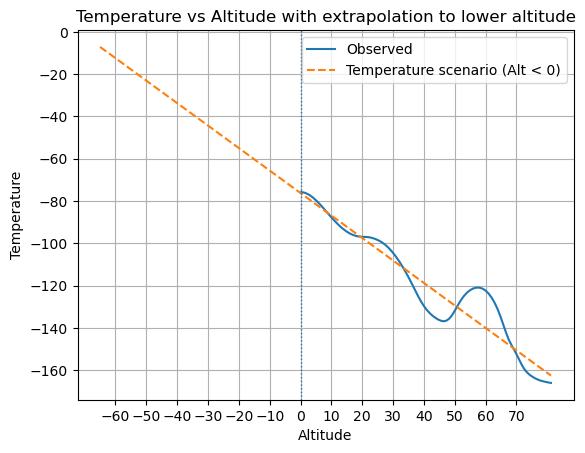

In [87]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

df_alt = data1.dropna(subset=["Alt", "Temp"]).copy()
df_alt = df_alt.sort_values("Alt")

x = df_alt["Alt"].to_numpy()
y = df_alt["Temp"].to_numpy()

def temp_model(alt, a, b):
    return a + b * alt

params, _ = curve_fit(temp_model, x, y)
a_hat, b_hat = params

print("Intercept (a):", a_hat)
print("Slope (b):", b_hat)

alt_min_neg = -65
alt_max = x.max()

alt_ext = np.linspace(alt_min_neg, alt_max, 400)
temp_fit = temp_model(alt_ext, a_hat, b_hat)


plt.figure()
plt.plot(x, y, label="Observed")
plt.plot(alt_ext, temp_fit, "--", label="Temperature scenario (Alt < 0)")
plt.axvline(0, linestyle=":", linewidth=1)

plt.xlabel("Altitude")
plt.ylabel("Temperature")
plt.title("Temperature vs Altitude with extrapolation to lower altitude")
plt.legend()
plt.xticks(range(-60, 80, 10))
plt.grid()
plt.show()